# Final Evaluation

Evaluation of stemmed BM25, dense E5, hybrid RRF and hybrid RRF + cross-encoder reranking on evaluation set. RAG selection excluded because it had weak performance at high processing time on the development set.

Code not commented in the same level of detail as in other notebooks where logic is really close to similar implementations in previous notebooks.

In [1]:
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from nltk.stem.snowball import SnowballStemmer
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder, SentenceTransformer

from scipy.stats import binomtest

/Users/samulepisto/Sebrain/04_projects/study/data-science/NLP/project/semantic-search/semantic-product-search/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1103 09:49:48.590000 44343 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## 1 Data Loading

In [2]:
# catalogue
catalog = pd.read_csv('../data/clean/catalog_clean.csv')
catalog = catalog.drop_duplicates(subset=['product_number']).reset_index(drop=True)
catalog['search_text'] = catalog['search_text'].fillna(catalog['clean_label']).fillna('')

# evaluation set
evaluation = pd.read_csv('../data/clean/test_set_eval.csv').rename(columns={
    'gold_product_number': 'gold_product_numbers',
    'product_label': 'gold_product_names'
})

# cached normalized E5 product embeddings
product_embeddings = np.load('../data/clean/indexes/product_embeddings_e5_base.npy')

In [3]:
# group eval rows by unique cleaned query
evaluation_queries = evaluation.groupby('clean_query').agg({
    'gold_product_numbers': lambda product_numbers: set(product_numbers),
    'gold_product_names': lambda names: list(dict.fromkeys(names)),
    'area_name': 'first',
    'request': 'first'
}).reset_index()

# show basic final-evaluation dimensions
print(f"Catalog unique products: {len(catalog)}")
print(f"Evaluation rows: {len(evaluation)}")
print(f"Evaluation unique queries: {len(evaluation_queries)}")
print(f"Cached product embeddings: {product_embeddings.shape}")
print("\nQueries by category:")
print(evaluation_queries['area_name'].value_counts())

Catalog unique products: 70720
Evaluation rows: 428
Evaluation unique queries: 272
Cached product embeddings: (70720, 768)

Queries by category:
area_name
Käsityökalut                                 58
Työturvallisuus                              51
Tekniset kemikaalit/-tarvikkeet, teipit      40
Materiaalin mekaaninen työstö                30
Työmaa tarvikkeet ja -varusteet              24
Koneet                                       21
Mittaaminen                                  17
Kiinnitystarvikkeet                          16
Hitsaus, polttoleikkaus, juotos, lämmitys     9
Ajoneuvolaitteet, -tarvikkeet                 2
Suorakiinnitys                                2
Helat, kaluste-, ovi-, ikkunatarvikkeet       1
Ankkurointitekniikka                          1
Name: count, dtype: int64


## 2 Evaluation Functions

Changes from previous notebooks evaluation_method:

- Query-level results retained, by the evaluate function itself not running the methods itself and not aggregating results already, but just doing the pure evaluation (individual query level results needed for results matrix, category results, McNemar tests and MRR bootstrapping)
- Recall@20 added
- First-gold search extended to top 20 for MRR

Additionally added

- Aggregation function aggregating now query-level values into one method-level result row

In [4]:
# now evaluate_ranking just receives the finished rankings and gold number for one query and returns query level metrics
def evaluate_ranking(product_numbers, gold_product_numbers):
    # top-20 cutoff (BM25 and dense return 100 for later use in hybrid retrieval)
    product_numbers = product_numbers[:20]

    # find first gold rank
    first_gold_rank = None
    for rank, product in enumerate(product_numbers, start=1):
        if product in gold_product_numbers:
            first_gold_rank = rank
            break

    # Hit and Recall metrics
    hit1 = first_gold_rank == 1
    recall5 = first_gold_rank is not None and first_gold_rank <= 5
    recall10 = first_gold_rank is not None and first_gold_rank <= 10
    recall20 = first_gold_rank is not None

    # MRR
    reciprocal_rank = 1.0 / first_gold_rank if first_gold_rank is not None else 0.0

    # nDCG@5
    dcg5 = sum(1.0 / np.log2(i + 1) for i, product in enumerate(product_numbers[:5], start=1) if product in gold_product_numbers)
    ideal_hits = min(len(gold_product_numbers), 5)
    idcg5 = sum(1.0 / np.log2(i + 1) for i in range(1, ideal_hits + 1))
    ndcg5 = dcg5 / idcg5 if idcg5 > 0 else 0.0

    # return query-level evaluation values
    return {
        'first_gold_rank': first_gold_rank,
        'Hit@1': hit1,
        'Recall@5': recall5,
        'Recall@10': recall10,
        'Recall@20': recall20,
        'reciprocal_rank': reciprocal_rank,
        'nDCG@5': ndcg5
    }

In [5]:
# aggregate query-level values into method-level result row
def aggregate_metrics(method_name, query_results, index_time_s):
    results_df = pd.DataFrame(query_results)

    return {
        'Method': method_name,
        'Hit@1': results_df['Hit@1'].mean(),
        'Recall@5': results_df['Recall@5'].mean(),
        'Recall@10': results_df['Recall@10'].mean(),
        'Recall@20': results_df['Recall@20'].mean(),
        'MRR': results_df['reciprocal_rank'].mean(),
        'nDCG@5': results_df['nDCG@5'].mean(),
        'Query latency (s)': results_df['query_latency_s'].mean(),
        'Indexing time (s)': index_time_s
    }

## 3 Method Implementation and Evaluation

### 3.1 Stemmed BM25

In [6]:
stemmer = SnowballStemmer("finnish")

def tokenize_stem(text):
    tokens = re.findall(r'\b\w+\b', text.lower())
    return [stemmer.stem(token) for token in tokens]
print("Tokenizing and stemming catalog products...")
t0 = time.time()
corpus_stem = [tokenize_stem(text) for text in catalog['search_text']]
bm25_stem = BM25Okapi(corpus_stem)
bm25_index_time_s = time.time() - t0
print(f"Indexed {len(corpus_stem)} stemmed products in {bm25_index_time_s:.2f} s")

Tokenizing and stemming catalog products...
Indexed 70720 stemmed products in 12.90 s


In [7]:
# search top 100 for later hybrid retrieval; dict instead of list, as it comes with labels here
def search_bm25_stem(query_text):
    tokens = tokenize_stem(query_text)
    if not tokens:
        return []
    scores = bm25_stem.get_scores(tokens)
    top_indices = np.argsort(scores)[::-1][:100]
    results = catalog.iloc[top_indices][['product_number', 'clean_label']].copy()
    results['score'] = scores[top_indices]
    return results.to_dict('records')

In [8]:
# query-level information and metrics
bm25_metrics_by_query = []
# detailed top-100 rankings by query
bm25_ranked_products_by_query = {}

print(f"Evaluating Stemmed BM25 on {len(evaluation_queries)} queries...")
# iterate over queries
for _, row in evaluation_queries.iterrows():
    query = row['clean_query']

    # do ranking and record latency
    t0 = time.time()
    ranking = search_bm25_stem(query)
    query_latency_s = time.time() - t0

    # collect metrics and product rankings
    product_numbers = [product['product_number'] for product in ranking]
    query_metrics = evaluate_ranking(product_numbers, row['gold_product_numbers'])
    query_metrics.update({
        'clean_query': query,
        'area_name': row['area_name'],
        'gold_product_numbers': row['gold_product_numbers'],
        'gold_product_names': row['gold_product_names'],
        'query_latency_s': query_latency_s
    })
    bm25_metrics_by_query.append(query_metrics)
    bm25_ranked_products_by_query[query] = ranking

# aggregate metrics for method
bm25_metrics_overall = aggregate_metrics('Stemmed BM25', bm25_metrics_by_query, bm25_index_time_s)
display(pd.DataFrame([bm25_metrics_overall]).round(4))

Evaluating Stemmed BM25 on 272 queries...


,Method,Hit@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@5,Query latency (s),Indexing time (s)
0,Stemmed BM25,0.1581,0.3309,0.4375,0.5074,0.2412,0.2486,0.0569,12.9049


### 3.2 Dense E5 Retrieval

In [9]:
if torch.backends.mps.is_available():
    device = "mps"
elif torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

print(f"Using device: {device}")

dense_model_name = "intfloat/multilingual-e5-base"
print(f"Loading embedding model '{dense_model_name}' on {device}...")
dense_model = SentenceTransformer(dense_model_name, device=device)

Using device: mps
Loading embedding model 'intfloat/multilingual-e5-base' on mps...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 5360.08it/s]


In [10]:
# search top 100 for later hybrid retrieval
def search_dense_e5(query_text):
    q_vec = dense_model.encode(f"query: {query_text}", normalize_embeddings=True)
    scores = np.dot(product_embeddings, q_vec)
    top_indices = np.argsort(scores)[::-1][:100]
    results = catalog.iloc[top_indices][['product_number', 'clean_label']].copy()
    results['score'] = scores[top_indices]
    return results.to_dict('records')

In [11]:
# analogous to BM25 implementation
dense_metrics_by_query = []
dense_ranked_products_by_query = {}

print(f"Evaluating Dense E5 on {len(evaluation_queries)} queries...")
for _, row in evaluation_queries.iterrows():
    query = row['clean_query']

    t0 = time.time()
    ranking = search_dense_e5(query)
    query_latency_s = time.time() - t0

    product_numbers = [product['product_number'] for product in ranking]
    query_metrics = evaluate_ranking(product_numbers, row['gold_product_numbers'])
    query_metrics.update({
        'clean_query': query,
        'area_name': row['area_name'],
        'gold_product_numbers': row['gold_product_numbers'],
        'gold_product_names': row['gold_product_names'],
        'query_latency_s': query_latency_s
    })

    dense_metrics_by_query.append(query_metrics)
    dense_ranked_products_by_query[query] = ranking

dense_metrics_overall = aggregate_metrics('Dense E5', dense_metrics_by_query, np.nan)
display(pd.DataFrame([dense_metrics_overall]).round(4))

Evaluating Dense E5 on 272 queries...


,Method,Hit@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@5,Query latency (s),Indexing time (s)
0,Dense E5,0.1507,0.3162,0.4044,0.4853,0.2275,0.232,0.0274,NaN


### 3.3 Hybrid RRF Retrieval

In [12]:
def search_hybrid_rrf(query_text):
    rrf_scores = {}
    clean_labels = {}

    for rank, product in enumerate(bm25_ranked_products_by_query[query_text], start=1):
        product_number = product['product_number']
        rrf_scores[product_number] = 1.0 / (60 + rank)
        clean_labels[product_number] = product['clean_label']

    for rank, product in enumerate(dense_ranked_products_by_query[query_text], start=1):
        product_number = product['product_number']
        rrf_scores[product_number] = rrf_scores.get(product_number, 0.0) + 1.0 / (60 + rank)
        clean_labels[product_number] = product['clean_label']

    ranked_products = sorted(rrf_scores, key=rrf_scores.get, reverse=True)[:20]
    return [{'product_number': product_number, 'clean_label': clean_labels[product_number], 'score': rrf_scores[product_number]} for product_number in ranked_products]

In [13]:
hybrid_metrics_by_query = []
hybrid_ranked_products_by_query = {}

# retrieve bm25 and dense latency because they have to be added to hybrid latency for full picture
bm25_latency_s = {result['clean_query']: result['query_latency_s'] for result in bm25_metrics_by_query}
dense_latency_s = {result['clean_query']: result['query_latency_s'] for result in dense_metrics_by_query}

print(f"Evaluating Hybrid RRF on {len(evaluation_queries)} queries...")
for _, row in evaluation_queries.iterrows():
    query = row['clean_query']

    t0 = time.time()
    ranking = search_hybrid_rrf(query)
    fusion_latency_s = time.time() - t0
    query_latency_s = bm25_latency_s[query] + dense_latency_s[query] + fusion_latency_s

    product_numbers = [product['product_number'] for product in ranking]
    query_metrics = evaluate_ranking(product_numbers, row['gold_product_numbers'])
    query_metrics.update({
        'clean_query': query,
        'area_name': row['area_name'],
        'gold_product_numbers': row['gold_product_numbers'],
        'gold_product_names': row['gold_product_names'],
        'query_latency_s': query_latency_s
    })

    hybrid_metrics_by_query.append(query_metrics)
    hybrid_ranked_products_by_query[query] = ranking

hybrid_metrics_overall = aggregate_metrics('Hybrid RRF', hybrid_metrics_by_query, np.nan)
display(pd.DataFrame([hybrid_metrics_overall]).round(4))

Evaluating Hybrid RRF on 272 queries...


,Method,Hit@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@5,Query latency (s),Indexing time (s)
0,Hybrid RRF,0.1581,0.4265,0.5331,0.6029,0.2742,0.2934,0.0844,NaN


### 3.4 Cross-Encoder Reranking

In [14]:
# create hybrid candidate table
hybrid_candidate_records = []
for query, ranking in hybrid_ranked_products_by_query.items():
    for rank, product in enumerate(ranking, start=1):
        hybrid_candidate_records.append({
            'clean_query': query,
            'hybrid_rank': rank,
            'product_number': product['product_number'],
            'clean_label': product['clean_label'],
            'hybrid_score': product['score']
        })

hybrid_candidates = pd.DataFrame(hybrid_candidate_records)

# join search text on candidate products
hybrid_candidates = hybrid_candidates.merge(
    catalog[['product_number', 'search_text']],
    on='product_number',
    how='left'
)

print(f"Hybrid candidate rows: {len(hybrid_candidates)}")
hybrid_candidates.head(3)

Hybrid candidate rows: 5440


,clean_query,hybrid_rank,product_number,clean_label,hybrid_score,search_text
0,10. akkuruuviväännin – 18 v,1,9999088794,käsine eureka 18-5 supercool harmaa 10,0.030835,käsine eureka 18-5 supercool harmaa 10
1,10. akkuruuviväännin – 18 v,2,5705812000,akkulaturi alg 18/12,0.023536,akkulaturi alg 18/12 alg 18 v m-cube -laturi o...
2,10. akkuruuviväännin – 18 v,3,5705808000,akkulaturi alg 18/8,0.022886,akkulaturi alg 18/8 alg 18 v m-cube -laturi on...


In [15]:
reranker_model_name = "BAAI/bge-reranker-v2-m3"
print(f"Loading cross-encoder '{reranker_model_name}' on {device}...")
reranker = CrossEncoder(reranker_model_name, device=device, max_length=512)
print("Cross-encoder loaded.")

Loading cross-encoder 'BAAI/bge-reranker-v2-m3' on mps...


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 8463.42it/s]


Cross-encoder loaded.


In [16]:
def rerank_candidates(query_text):
    query_candidates = hybrid_candidates[
        hybrid_candidates['clean_query'] == query_text
    ].copy()

    query_product_pairs = [
        (query_text, search_text)
        for search_text in query_candidates['search_text']
    ]

    query_candidates['score'] = reranker.predict(
        query_product_pairs,
        batch_size=4,
        show_progress_bar=False
    )

    query_candidates = query_candidates.sort_values(
        by=['score', 'hybrid_rank'],
        ascending=[False, True]
    ).reset_index(drop=True)

    return query_candidates[['product_number', 'clean_label', 'score']].head(20).to_dict('records')

In [17]:
reranker_metrics_by_query = []
reranker_ranked_products_by_query = {}
hybrid_latency_s = {result['clean_query']: result['query_latency_s'] for result in hybrid_metrics_by_query}

print(f"Evaluating Cross-Encoder Reranking on {len(evaluation_queries)} queries...")
for _, row in evaluation_queries.iterrows():
    query = row['clean_query']

    t0 = time.time()
    ranking = rerank_candidates(query)
    reranking_latency_s = time.time() - t0
    query_latency_s = hybrid_latency_s[query] + reranking_latency_s

    product_numbers = [product['product_number'] for product in ranking]
    query_metrics = evaluate_ranking(product_numbers, row['gold_product_numbers'])
    query_metrics.update({
        'clean_query': query,
        'area_name': row['area_name'],
        'gold_product_numbers': row['gold_product_numbers'],
        'gold_product_names': row['gold_product_names'],
        'query_latency_s': query_latency_s
    })

    reranker_metrics_by_query.append(query_metrics)
    reranker_ranked_products_by_query[query] = ranking

reranker_metrics_overall = aggregate_metrics('Hybrid RRF + Cross-Encoder', reranker_metrics_by_query, np.nan)
display(pd.DataFrame([reranker_metrics_overall]).round(4))

Evaluating Cross-Encoder Reranking on 272 queries...


,Method,Hit@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@5,Query latency (s),Indexing time (s)
0,Hybrid RRF + Cross-Encoder,0.3015,0.5,0.5699,0.6029,0.3931,0.4016,1.3496,NaN


## 4 Final Evaluation

### 4.1 Query × Method–Product Matrix

Detailed results matrix

In [18]:
ranked_products_by_method = {
    'Stemmed BM25': bm25_ranked_products_by_query,
    'Dense E5': dense_ranked_products_by_query,
    'Hybrid RRF': hybrid_ranked_products_by_query,
    'Hybrid RRF + Cross-Encoder': reranker_ranked_products_by_query
}

matrix_records = []
for _, row in evaluation_queries.iterrows():
    query = row['clean_query']
    matrix_record = {
        'clean_query': query,
        'area_name': row['area_name'],
        'gold_product_numbers': row['gold_product_numbers'],
        'gold_product_names': row['gold_product_names']
    }

    for method_name, rankings in ranked_products_by_method.items():
        top_product = rankings[query][0]
        matrix_record[f'{method_name} product_number'] = top_product['product_number']
        matrix_record[f'{method_name} product name'] = top_product['clean_label']
        matrix_record[f'{method_name} score'] = top_product['score']

    matrix_records.append(matrix_record)

query_method_matrix = pd.DataFrame(matrix_records)
display(query_method_matrix.head(10))

,clean_query,area_name,gold_product_numbers,gold_product_names,Stemmed BM25 product_number,Stemmed BM25 product name,Stemmed BM25 score,Dense E5 product_number,Dense E5 product name,Dense E5 score,Hybrid RRF product_number,Hybrid RRF product name,Hybrid RRF score,Hybrid RRF + Cross-Encoder product_number,Hybrid RRF + Cross-Encoder product name,Hybrid RRF + Cross-Encoder score
0,10. akkuruuviväännin – 18 v,Koneet,{5705180000},[AKKULATURI ALG 18/4 BASIC],5705812000,akkulaturi alg 18/12,13.499177,5801800015,vyöklipsi 18v m-cube akkuporiin,0.852495,9999088794,käsine eureka 18-5 supercool harmaa 10,0.030835,5801800015,vyöklipsi 18v m-cube akkuporiin,0.349489
1,12v h7 long life polttimo 55w eco,"Ajoneuvolaitteet, -tarvikkeet",{072011412},[POLTTIMO H7 12V 55W LONGLIFE 12972],07207141,polttimo h7 12v 55w 12972,45.332810,07207141,polttimo h7 12v 55w 12972,0.875870,07207141,polttimo h7 12v 55w 12972,0.032787,072011412,polttimo h7 12v 55w longlife 12972,0.983346
2,8. akkuruuviväännin – 12 v,Koneet,{5700130002},[AKKUPORA BS12-A],0510955821,akkulaturi 12/24v 15a,11.872500,5700132000,"akkuiskuruuvinväännin ass 12-a, runko",0.858016,5700132000,"akkuiskuruuvinväännin ass 12-a, runko",0.031778,5700132002,akkuiskuruuvinväännin ass 12-a 2.0ah,0.891327
3,9. akkuruuviväännin – 18 v,Koneet,{5701427000},"[AKKUPORA ABS 18 COMPACT, RUNKO]",5705808000,akkulaturi alg 18/8,13.499177,5801800015,vyöklipsi 18v m-cube akkuporiin,0.858831,9999088793,käsine eureka 18-5 supercool harmaa 9,0.030310,5801800015,vyöklipsi 18v m-cube akkuporiin,0.287762
4,"a-tikkaat => 4 askelmaa, n. 1400mm korkea",Työmaa tarvikkeet ja -varusteet,{0962975403},[AMMATTITASOTIKAS WÜRTH PRO 3 ASK],0962941604,askelmatikas lg 4 askelmaa,30.051474,018277440,yleisruuvi uppokanta a4 4x40,0.875487,9999093698,"taloustikas 5 askelmaa, 1000mm",0.028175,0962941604,askelmatikas lg 4 askelmaa,0.880434
5,adblue 210l,"Tekniset kemikaalit/-tarvikkeet, teipit",{089062 200},[ADBLUE 200L],0891700092,adblue automaattinen tankkauspistooli,15.079259,089062 200,adblue 200l,0.867025,089062 200,adblue 200l,0.030478,9501006311,delphin pro adblue automaattipumppusetti,0.763789
6,"akku bl1860b 18v 6,0 ah",Koneet,{5703550000},"[AKKU LI-ION 18V/5,0AH M-CUBE W-CONNECT]",9999082818,"akku m18 b5 5,0 ah lion",27.081124,0700956331,"akku li-12v/3,0ah",0.873351,9999082818,"akku m18 b5 5,0 ah lion",0.031545,0700916535,"akku li-ion 18v/5,0 ah",0.369491
7,akku makita 5ah bulk,Koneet,{5703550000},"[AKKU LI-ION 18V/5,0AH M-CUBE W-CONNECT]",0864903,akku diga 6v 1.5ah nimh,24.186192,9999093321,makita teräketjuöljy 5l,0.888266,9999093321,makita teräketjuöljy 5l,0.031319,9999082818,"akku m18 b5 5,0 ah lion",0.202395
8,akkulaturi (yhteensopiva tarjottujen akkujen k...,Koneet,{5705808000},[AKKULATURI ALG 18/8],9501006316,akkulaturi pika aa/aaa energizer 230vac,22.775916,5701700007,käsisuutin akkuimuriin amts,0.862842,9501006316,akkulaturi pika aa/aaa energizer 230vac,0.032266,0510956125,korjaamolaturi defa 125a 12/24v,0.789587
9,akkuporakone,Koneet,{5701427000},"[AKKUPORA ABS 18 COMPACT, RUNKO]",0706615003,lisäkahva bs power akkuporakoneisiin,8.872583,5701101002,"akkupora abs 12 compact, 2x2.0ah",0.864271,0706615003,lisäkahva bs power akkuporakoneisiin,0.032522,5700130002,akkupora bs12-a,0.985081


### 4.2 Overall Results

,Method,Hit@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@5,Query latency (s),Indexing time (s)
0,Stemmed BM25,0.1581,0.3309,0.4375,0.5074,0.2412,0.2486,0.0569,12.9049
1,Dense E5,0.1507,0.3162,0.4044,0.4853,0.2275,0.2320,0.0274,NaN
2,Hybrid RRF,0.1581,0.4265,0.5331,0.6029,0.2742,0.2934,0.0844,NaN
3,Hybrid RRF + Cross-Encoder,0.3015,0.5000,0.5699,0.6029,0.3931,0.4016,1.3496,NaN


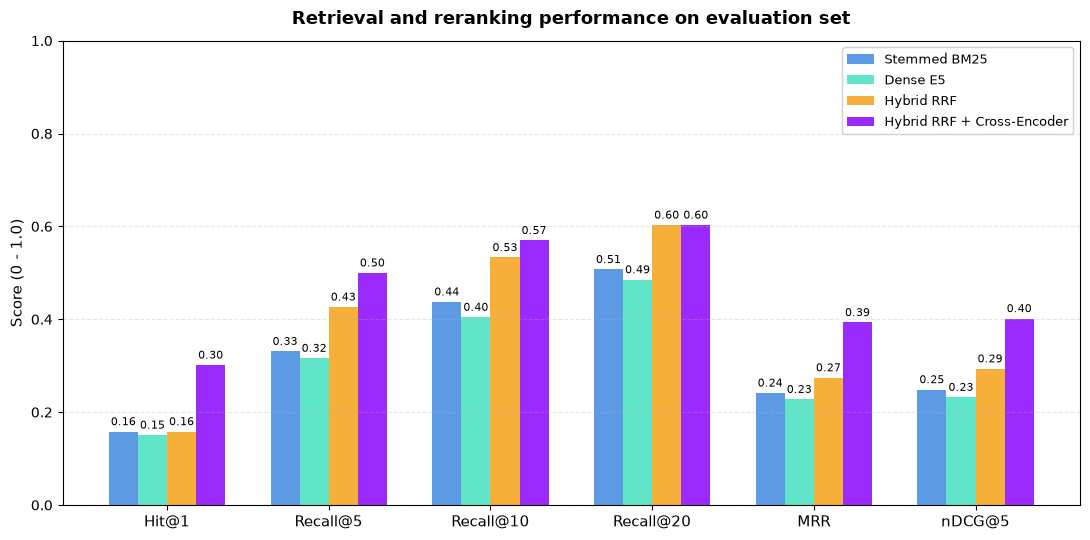

In [19]:
overall_results = pd.DataFrame([
    bm25_metrics_overall,
    dense_metrics_overall,
    hybrid_metrics_overall,
    reranker_metrics_overall
])
display(overall_results.round(4))

# plot comparison of retrieval metrics across all methods
plt.style.use('default')
metrics = ['Hit@1', 'Recall@5', 'Recall@10', 'Recall@20', 'MRR', 'nDCG@5']
n_methods = len(overall_results)

x = np.arange(len(metrics))
width = 0.18

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ['#4A90E2', '#50E3C2', '#F5A623', '#9013FE']

for i, row in overall_results.iterrows():
    vals = [row[m] for m in metrics]
    bars = ax.bar(x + (i - (n_methods - 1) / 2) * width, vals, width, label=row['Method'], color=colors[i % len(colors)], alpha=0.9)
    # add data labels
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.008, f"{h:.2f}", ha='center', va='bottom', fontsize=8, rotation=0)

ax.set_ylabel('Score (0 - 1.0)', fontsize=11)
ax.set_title('Retrieval and reranking performance on evaluation set', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 1)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

- Stemmed BM25 performs slightly better than dense E5 at negligibly higher latency
- Hybrid RRF improves retrieval over single methods (Recall@20 improved from 0.5 of stemmed BM25 and 0.49 of dense retrieval to 0.6 of hybrid retrieval)
- Cross-encoder reranking improves Hit@1 (remarkable jump from 0.16 without to 0.3 with reranking); Reranking can't make up for cases, where candidate generation failed -> investigate losses along pipeline in detail

### 4.3 Category-Specific Results


Käsityökalut (Hand tools)


,Hit@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@5,Query latency (s)
Method,,,,,,,
Stemmed BM25,0.2931,0.5172,0.5690,0.5690,0.3786,0.4090,0.0669
Dense E5,0.1379,0.2241,0.3103,0.3793,0.1904,0.1817,0.0288
Hybrid RRF,0.2069,0.4483,0.5690,0.6552,0.3273,0.3261,0.0958
Hybrid RRF + Cross-Encoder,0.3793,0.5172,0.5862,0.6552,0.4535,0.4338,1.0472


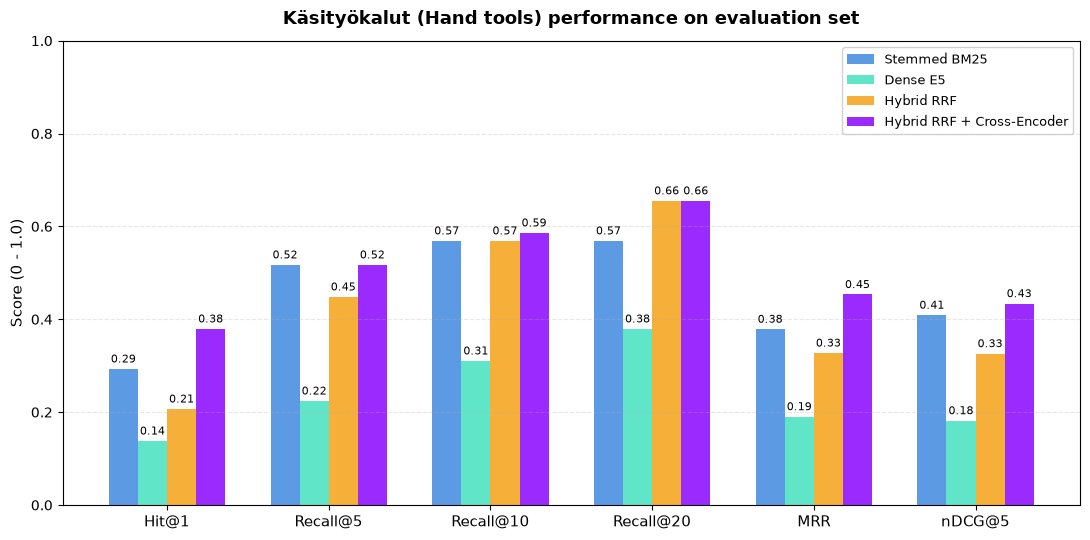


Työturvallisuus (Occupational safety)


,Hit@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@5,Query latency (s)
Method,,,,,,,
Stemmed BM25,0.1176,0.2157,0.2941,0.3529,0.1578,0.1604,0.0467
Dense E5,0.0588,0.2157,0.2745,0.3137,0.1274,0.1405,0.0186
Hybrid RRF,0.0784,0.1961,0.3333,0.3725,0.1464,0.1436,0.0654
Hybrid RRF + Cross-Encoder,0.1373,0.2549,0.3333,0.3725,0.1852,0.1865,1.5232


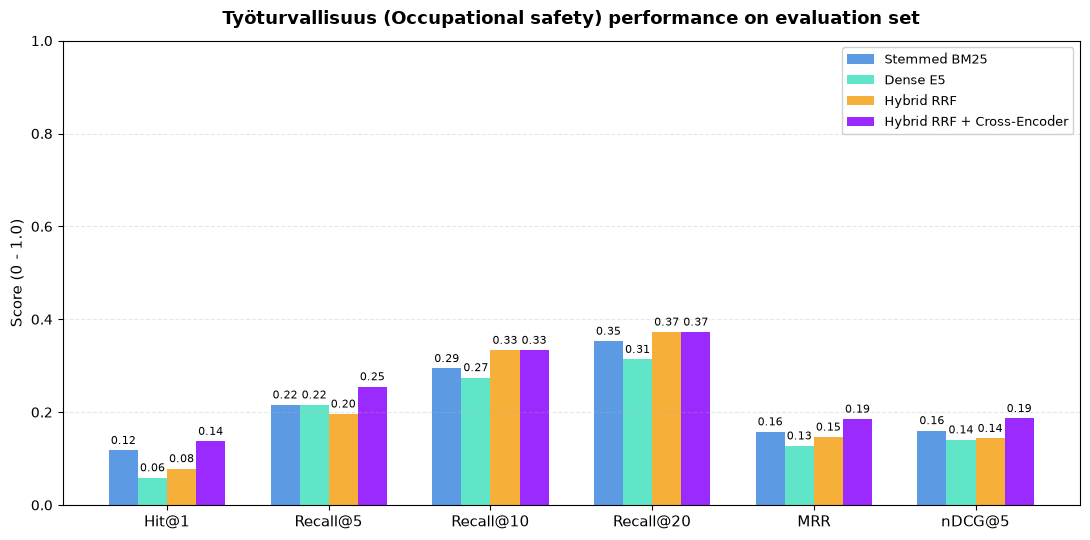


Tekniset kemikaalit/-tarvikkeet, teipit (Technical chemicals, accessories and tapes)


,Hit@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@5,Query latency (s)
Method,,,,,,,
Stemmed BM25,0.100,0.200,0.425,0.575,0.1866,0.1598,0.0445
Dense E5,0.350,0.600,0.700,0.825,0.4566,0.4746,0.0243
Hybrid RRF,0.325,0.725,0.775,0.800,0.4665,0.5236,0.0688
Hybrid RRF + Cross-Encoder,0.450,0.775,0.800,0.800,0.5948,0.6385,1.5456


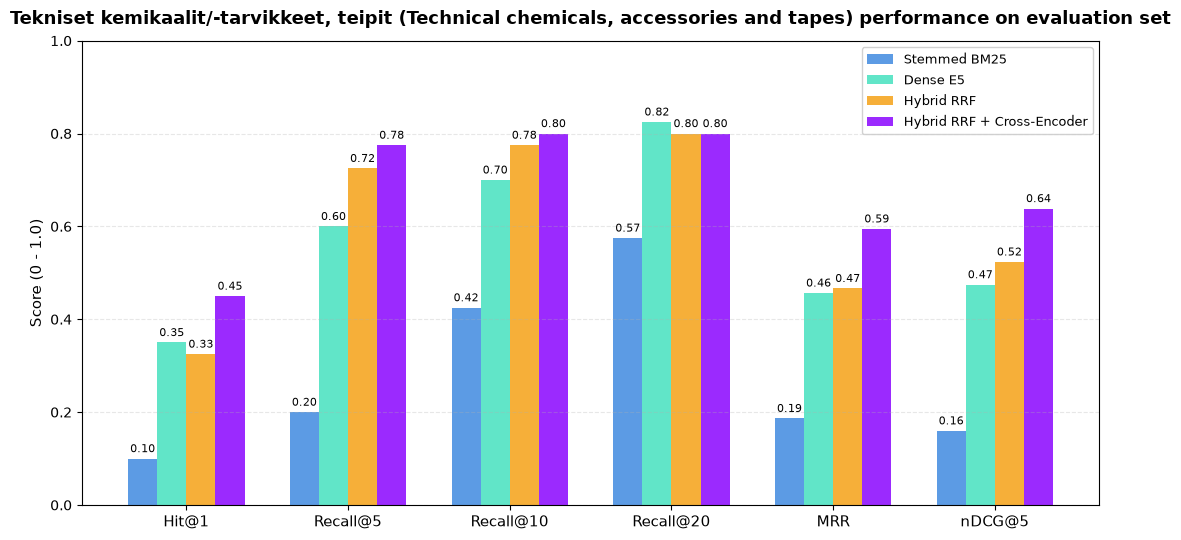


Materiaalin mekaaninen työstö (Mechanical material processing)


,Hit@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@5,Query latency (s)
Method,,,,,,,
Stemmed BM25,0.1000,0.3000,0.3667,0.4667,0.1872,0.2026,0.0515
Dense E5,0.1000,0.2000,0.3333,0.4000,0.1491,0.1439,0.0255
Hybrid RRF,0.1333,0.4000,0.4000,0.4667,0.2199,0.2603,0.0770
Hybrid RRF + Cross-Encoder,0.2667,0.4333,0.4333,0.4667,0.3475,0.3675,1.4612


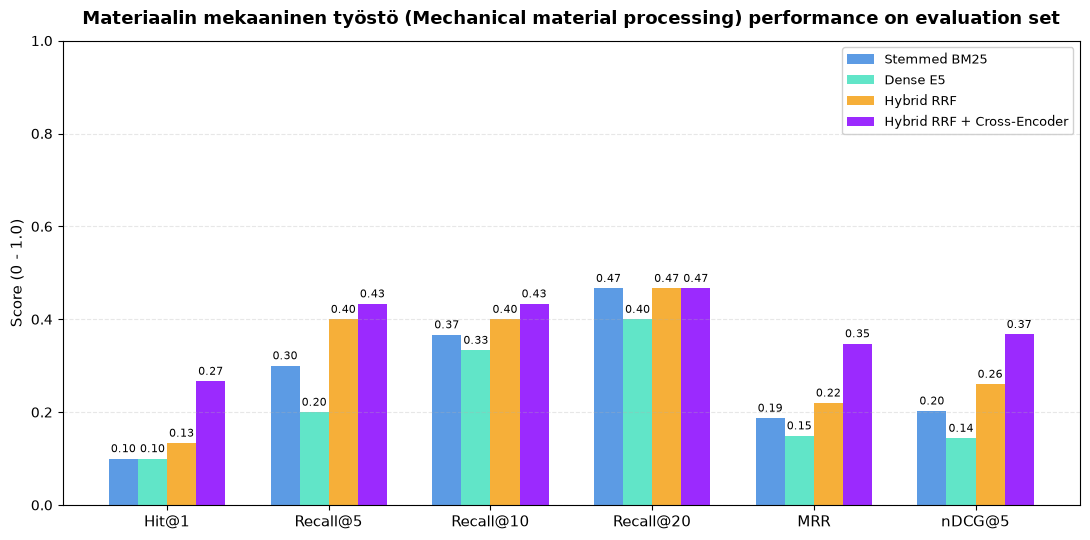


Työmaa tarvikkeet ja -varusteet (Construction site supplies and equipment)


,Hit@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@5,Query latency (s)
Method,,,,,,,
Stemmed BM25,0.2083,0.4583,0.7083,0.7917,0.3383,0.3310,0.0510
Dense E5,0.2500,0.5833,0.6667,0.7917,0.3964,0.4183,0.0199
Hybrid RRF,0.3333,0.7083,0.8333,0.9167,0.4504,0.4852,0.0710
Hybrid RRF + Cross-Encoder,0.5000,0.7500,0.9167,0.9167,0.6290,0.6414,1.2087


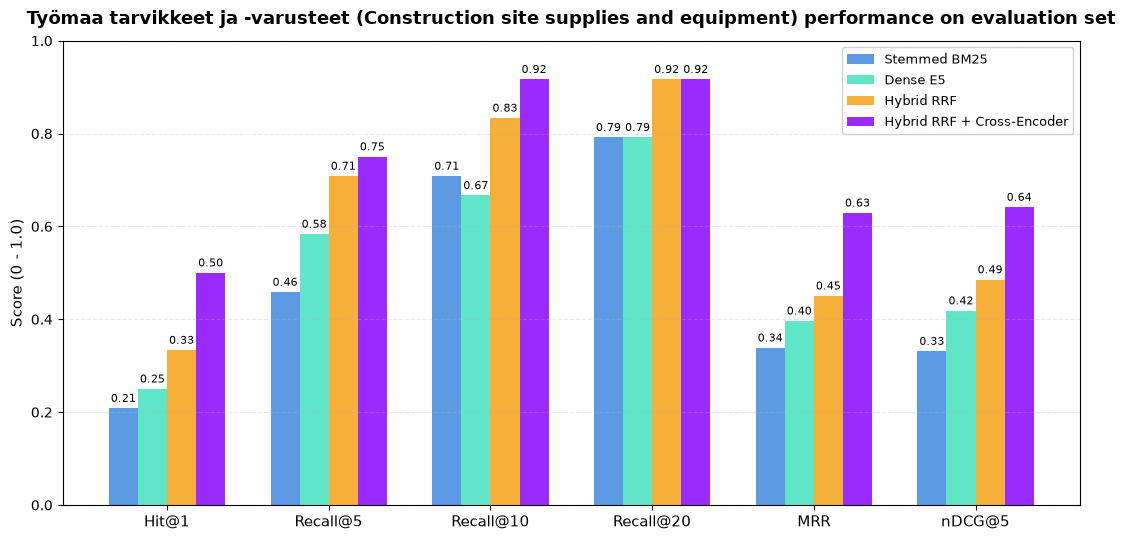

In [20]:
metrics_by_method = {
    'Stemmed BM25': bm25_metrics_by_query,
    'Dense E5': dense_metrics_by_query,
    'Hybrid RRF': hybrid_metrics_by_query,
    'Hybrid RRF + Cross-Encoder': reranker_metrics_by_query
}

category_names_en = {
    'Työturvallisuus': 'Occupational safety',
    'Tekniset kemikaalit/-tarvikkeet, teipit': 'Technical chemicals, accessories and tapes',
    'Materiaalin mekaaninen työstö': 'Mechanical material processing',
    'Käsityökalut': 'Hand tools',
    'Työmaa tarvikkeet ja -varusteet': 'Construction site supplies and equipment'
}

cat_records = []
for method_name, query_metrics in metrics_by_method.items():
    for result in query_metrics:
        cat_records.append({
            'Method': method_name,
            'area_name': result['area_name'],
            'Hit@1': result['Hit@1'],
            'Recall@5': result['Recall@5'],
            'Recall@10': result['Recall@10'],
            'Recall@20': result['Recall@20'],
            'MRR': result['reciprocal_rank'],
            'nDCG@5': result['nDCG@5'],
            'Query latency (s)': result['query_latency_s']
        })

df_cat = pd.DataFrame(cat_records)
top_cats = evaluation_queries['area_name'].value_counts().head(5).index

category_metric_columns = [
    'Hit@1', 'Recall@5', 'Recall@10', 'Recall@20',
    'MRR', 'nDCG@5', 'Query latency (s)'
]
category_results = df_cat[df_cat['area_name'].isin(top_cats)].groupby(
    ['area_name', 'Method']
)[category_metric_columns].mean().reset_index()
category_results['area_name_en'] = category_results['area_name'].map(category_names_en)

plt.style.use('default')
metrics = ['Hit@1', 'Recall@5', 'Recall@10', 'Recall@20', 'MRR', 'nDCG@5']

for category in top_cats:
    category_name = f"{category} ({category_names_en[category]})"
    print(f"\n{category_name}")
    category_table = category_results[category_results['area_name'] == category].set_index('Method')
    category_table = category_table.reindex(metrics_by_method)
    display(category_table[category_metric_columns].round(4))

    category_plot_df = category_table.reset_index()
    n_methods = len(category_plot_df)

    x = np.arange(len(metrics))
    width = 0.18

    fig, ax = plt.subplots(figsize=(11, 5.5))
    colors = ['#4A90E2', '#50E3C2', '#F5A623', '#9013FE']

    for i, row in category_plot_df.iterrows():
        vals = [row[m] for m in metrics]
        bars = ax.bar(x + (i - (n_methods - 1) / 2) * width, vals, width, label=row['Method'], color=colors[i % len(colors)], alpha=0.9)
        # add data labels
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, h + 0.008, f"{h:.2f}", ha='center', va='bottom', fontsize=8, rotation=0)

    ax.set_ylabel('Score (0 - 1.0)', fontsize=11)
    ax.set_title(f'{category_name} performance on evaluation set', fontsize=13, fontweight='bold', pad=12)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, fontsize=11)
    ax.set_ylim(0, 1)
    ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

Overall category performance seems to strongly depend on variable candidate generation performance of methods, while reranking seems to be rather effective across categories
- Hand tools: Remarkably strong stemmed BM25 results. However, no point in switching from generally best performing hybrid retrieval as hybrid retrieval still has slightly better Recall@20
- Occupational safety: Most challenging category with hybrid Recall@20 only 0.37 and reranked Hit@1 only 0.14
- Technical chemicals and accessories: Only category where dense recall@20 slightly exceeds hybrid
- Mechanical material processing: Well performing reranking but limited candidate retrieval
- Construction site supplies: strongest category

### 4.4 Final Candidate Generation and Reranking Performance

In [21]:
# Retrieve R20, H1 and R5 per query
hybrid_recall20_by_query = pd.DataFrame(hybrid_metrics_by_query)[['clean_query', 'area_name', 'Recall@20']]
reranker_results_by_query = pd.DataFrame(reranker_metrics_by_query)[['clean_query', 'Hit@1', 'Recall@5']].rename(columns={
    'Hit@1': 'reranker_hit1',
    'Recall@5': 'reranker_recall5'
})
# Combine them
candidate_reranking_outcomes = hybrid_recall20_by_query.merge(reranker_results_by_query, on='clean_query')

# Calculate Overall Results
candidate_reranking_records = []
overall_queries_with_gold_in_top20 = candidate_reranking_outcomes[candidate_reranking_outcomes['Recall@20']]
candidate_reranking_records.append({
    'Scope': 'Overall',
    'Hybrid Recall@20 (%)': candidate_reranking_outcomes['Recall@20'].mean() * 100,
    'Conditional reranker Hit@1 (%)': overall_queries_with_gold_in_top20['reranker_hit1'].mean() * 100,
    'Conditional reranker Recall@5 (%)': overall_queries_with_gold_in_top20['reranker_recall5'].mean() * 100
})

# Calculate Results per Category
for category in top_cats:
    cat_queries = candidate_reranking_outcomes[candidate_reranking_outcomes['area_name'] == category]
    cat_queries_with_gold_in_top20 = cat_queries[cat_queries['Recall@20']]
    candidate_reranking_records.append({
        'Scope': f"{category} ({category_names_en[category]})",
        'Hybrid Recall@20 (%)': cat_queries['Recall@20'].mean() * 100,
        'Conditional reranker Hit@1 (%)': cat_queries_with_gold_in_top20['reranker_hit1'].mean() * 100,
        'Conditional reranker Recall@5 (%)': cat_queries_with_gold_in_top20['reranker_recall5'].mean() * 100
    })

# create final comparison table
candidate_reranking_results = pd.DataFrame(candidate_reranking_records)
display(candidate_reranking_results.round(1))

,Scope,Hybrid Recall@20 (%),Conditional reranker Hit@1 (%),Conditional reranker Recall@5 (%)
0,Overall,60.3,50.0,82.9
1,Käsityökalut (Hand tools),65.5,57.9,78.9
2,Työturvallisuus (Occupational safety),37.3,36.8,68.4
3,"Tekniset kemikaalit/-tarvikkeet, teipit (Techn...",80.0,56.2,96.9
4,Materiaalin mekaaninen työstö (Mechanical mate...,46.7,57.1,92.9
5,Työmaa tarvikkeet ja -varusteet (Construction ...,91.7,54.5,81.8


- Recall@20 limited to on avg. 60% limiting possible downstream performance
- When a gold product gets retrieved, reranker is able to rank a gold product highest in 50% of the cases and in the top-5 in 82.9% of cases. While 50% might not be enough to justify a fully automated pipeline, 82.9% is a good result considering final judgement done by human
- Recall@20 exceptionally high for technical chemicals and accessories and construction site supplies, while low for occupational safety and mechanical material processing
- Conditional Hit@1 relatively stable across categories with occupational safety products being an exception among the top-5 categories

### 4.5 McNemar Tests

In [22]:
# define comparisons to be done
comparisons = [
    ('Stemmed BM25 vs Dense E5', 'Recall@20', bm25_metrics_by_query, dense_metrics_by_query),
    ('Stemmed BM25 vs Hybrid RRF', 'Recall@20', bm25_metrics_by_query, hybrid_metrics_by_query),
    ('Hybrid RRF vs Hybrid RRF + Cross-Encoder', 'Hit@1', hybrid_metrics_by_query, reranker_metrics_by_query)
]

mcnemar_records = []
# iterate over comparisons
for comparison, metric, first_results, second_results in comparisons:
    first_method_successes = np.array([result[metric] for result in first_results])
    second_method_successes = np.array([result[metric] for result in second_results])

    # count outcomes
    both_successful = sum(first_success and second_success for first_success, second_success in zip(first_method_successes, second_method_successes))
    first_only_successful = sum(first_success and not second_success for first_success, second_success in zip(first_method_successes, second_method_successes))
    second_only_successful = sum(not first_success and second_success for first_success, second_success in zip(first_method_successes, second_method_successes))
    both_unsuccessful = sum(not first_success and not second_success for first_success, second_success in zip(first_method_successes, second_method_successes))

    # calc pval
    different_outcomes = first_only_successful + second_only_successful
    p_value = binomtest(first_only_successful, different_outcomes, 0.5).pvalue

    # store comparison-specific result
    mcnemar_records.append({
        'Comparison': comparison,
        'Metric': metric,
        'Both successful': both_successful,
        'First only successful': first_only_successful,
        'Second only successful': second_only_successful,
        'Both unsuccessful': both_unsuccessful,
        'p-value': p_value
    })

# create final comparison table from comparison-specific results
mcnemar_results = pd.DataFrame(mcnemar_records)
display(mcnemar_results.round(4))

,Comparison,Metric,Both successful,First only successful,Second only successful,Both unsuccessful,p-value
0,Stemmed BM25 vs Dense E5,Recall@20,95,43,37,97,0.5764
1,Stemmed BM25 vs Hybrid RRF,Recall@20,130,8,34,100,0.0001
2,Hybrid RRF vs Hybrid RRF + Cross-Encoder,Hit@1,34,9,48,181,0.0000


Results support hybrid + reranking pipeline
- In line with prior results Dense E5 does not show significant improvement over BM25 by itself.
- Improvement of hybrid RRF over the best single candidate generation method, stemmed BM25, however, shows significant Recall@20 improvement.
- As does reranking over hybrid RRF alone for Hit@1.

### 4.6 Paired Bootstrap Confidence Intervals for MRR

In [23]:
# set seed and create result list
random_generator = np.random.default_rng(1234)
bootstrap_mrr_records = []

# iterate over same comparisons
for comparison, _, first_results, second_results in comparisons:
    # rr calc
    first_rr = np.array([result['reciprocal_rank'] for result in first_results])
    second_rr = np.array([result['reciprocal_rank'] for result in second_results])
    rr_diff = second_rr - first_rr

    # bootstrapping
    bootstrap_diffs = []
    for _ in range(500000):
        bootstrap_sample = random_generator.choice(rr_diff, size=len(rr_diff), replace=True)
        bootstrap_diffs.append(bootstrap_sample.mean())

    # calc 95% confidence interval
    ci_lower, ci_upper = np.percentile(bootstrap_diffs, [2.5, 97.5])

    # store comparison-specific results
    bootstrap_mrr_records.append({
        'Comparison': comparison,
        'First method MRR': first_rr.mean(),
        'Second method MRR': second_rr.mean(),
        'MRR difference': rr_diff.mean(),
        '95% CI lower': ci_lower,
        '95% CI upper': ci_upper
    })

# create final comparison table from comparison-specific results
bootstrap_mrr_results = pd.DataFrame(bootstrap_mrr_records)
display(bootstrap_mrr_results.round(4))

,Comparison,First method MRR,Second method MRR,MRR difference,95% CI lower,95% CI upper
0,Stemmed BM25 vs Dense E5,0.2412,0.2275,-0.0138,-0.0635,0.0361
1,Stemmed BM25 vs Hybrid RRF,0.2412,0.2742,0.0329,-0.0009,0.0674
2,Hybrid RRF vs Hybrid RRF + Cross-Encoder,0.2742,0.3931,0.1189,0.0825,0.1563


Results align with previous results
- BM25 -> Dense: no clear difference
- BM25 -> hybrid: likely improvement, but in terms of bootstrapping inconclusive, as CI includes 0
- Hybrid RRF -> Cross-Encoder: clear improvement

## 5 Overall Conclusion
- Stemmed BM25 slightly better than Dense E5, but hybrid still best candidate generation method overall significantly increasing Recall@20
- Cross-encoder reranking shows strong Hit@1 improvement; RAG not considered due to poor performance in development stage
- McNemar and bootstrap results generally support this (while Hybrid MRR improvement is inconclusive in bootstrapping)
- Candidate generation is a bottleneck, with no gold product included in generated candidates in 40% of cases
- When gold product is retrieved, reranking performs solid at 50% conditional Hit@1 and strong conditional Recall@5 of 82.9%
- However, overall and individual method performance still varies across categories
- Overall best performing pipeline is hybrid retrieval combined with cross-encoder reranking

## 6 Export Result Matrix

In [24]:
query_method_matrix.to_csv('../data/clean/final_evaluation_matrix.csv', index=False)
print("Final evaluation matrix saved to '../data/clean/final_evaluation_matrix.csv'")

Final evaluation matrix saved to '../data/clean/final_evaluation_matrix.csv'


In [25]:
# export data for error analysis

eval_overlap_records = []
for q in evaluation_queries['clean_query']:
    b20 = set(p['product_number'] for p in bm25_ranked_products_by_query[q][:20])
    d20 = set(p['product_number'] for p in dense_ranked_products_by_query[q][:20])
    common = b20 & d20
    union = b20 | d20
    eval_overlap_records.append({
        'clean_query': q,
        'common_count': len(common),
        'jaccard_similarity': len(common) / len(union) if union else 0.0,
        'zero_overlap': len(common) == 0
    })
pd.DataFrame(eval_overlap_records).to_csv('../data/clean/eval_overlap.csv', index=False)

# candidate reranking outcomes
candidate_reranking_outcomes.to_csv('../data/clean/eval_funnel.csv', index=False)
print("Saved eval_overlap.csv and eval_funnel.csv to data/clean/")

Saved eval_overlap.csv and eval_funnel.csv to data/clean/
